# Bump sensitivities by finite differences

Goal: the sensitivity of the free surface over a bump to its position x0 and width w, by central finite differences.

Next: [the same with forward-mode AD](bump_forward_ad.ipynb).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

from zoomy_core.mesh import LSQMesh
from zoomy_core.model.boundary_conditions import Dirichlet
from zoomy_core.model.models import SME
from zoomy_core.model.models.closures import Newtonian, StressFree
from zoomy_core.numerics import NumericalSystemModel, ReconstructionSpec
from zoomy_core.systemmodel import SystemModel
from zoomy_jax.symsolver.solver import AdMode, SymbolicHyperbolicSolverJax

In [2]:
s = SME.state(level=0, dimension=2)
model = SME(
    level=0, dimension=2, closures=[Newtonian(), StressFree()],
    boundary_conditions=[
        Dirichlet("left", on=s.q_0, value=1.0),
        Dirichlet("right", on=s.h, value=1.0 - s.b),
    ],
)
nsm = NumericalSystemModel.from_system_model(
    SystemModel.from_model(model), reconstruction=ReconstructionSpec(order=1))
mesh = LSQMesh.create_1d(domain=(0.0, 10.0), n_inner_cells=100)
solver = SymbolicHyperbolicSolverJax(time_end=10.0, dt=0.02, mood=False)
Q0, Qaux0 = solver.setup(mesh, nsm)
x = jnp.asarray(mesh.cell_centers[0, :Q0.shape[1]])
dx = float(x[1] - x[0])

In [3]:
def bed(p):
    x0, w = p
    return 0.2 * jnp.exp(-((x - x0) / w) ** 2)


def free_surface(b):
    rows = {s.b: b, s.h: 1.0 - b, s.q_0: jnp.ones_like(b)}
    Q = jnp.stack([rows[f] for f in s])
    Q = solver.run(Q, solver.initial_aux(Q, Qaux0)).Q
    return Q[s.slot(s.b)] + Q[s.slot(s.h)]


eta = jax.jit(lambda p: free_surface(bed(p)))
p0 = jnp.array([4.73, 0.8])
e = jnp.eye(2)

In [4]:
def central(f, p, v, eps):
    return (f(p + eps * v) - f(p - eps * v)) / (2 * eps)


eta0 = eta(p0)
deta = [central(eta, p0, e[k], 1e-4) for k in range(2)]
deta_coarse = [central(eta, p0, e[k], 1e-3) for k in range(2)]
change = max(float(jnp.abs(a - c).max() / jnp.abs(a).max())
             for a, c in zip(deta, deta_coarse))
print(f"relative change of the FD sensitivities, eps 1e-3 -> 1e-4: {change:.1e}")

relative change of the FD sensitivities, eps 1e-3 -> 1e-4: 1.8e-06


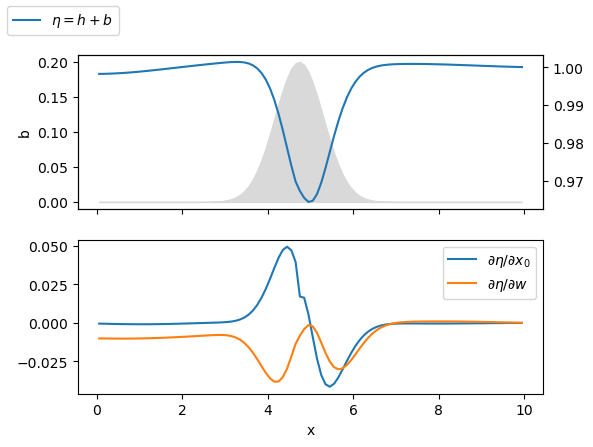

In [5]:
fig, (a, b) = plt.subplots(2, 1, figsize=(6, 4.4), sharex=True)
a.fill_between(x, 0.0, bed(p0), color="0.85")
a.set_ylabel("b")
a.twinx().plot(x, eta0, label=r"$\eta = h + b$")
a.figure.legend(loc="upper left")
b.plot(x, deta[0], label=r"$\partial\eta / \partial x_0$")
b.plot(x, deta[1], label=r"$\partial\eta / \partial w$")
b.set_xlabel("x")
b.legend()
plt.show()

In [6]:
assert change < 1e-5